In [1]:
from amplpy import AMPL, ampl_notebook

ampl = ampl_notebook(
    modules=["gurobi", "xpress"],  # modules to install
    license_uuid="your-license-uuid",  # license to use
)  # instantiate AMPL object and register magics


In [4]:
import pandas as pd

power_plants =df= pd.DataFrame(
        {
        "Capacity_MW": [500, 600, 400, 450, 1000, 200, 300],
        "Cost_per_MW": [50, 55, 40, 42, 30, 0, 0],  # Solar & Wind have no fuel cost
        "CO2_Emission_per_MW": [1.2, 1.1, 0.5, 0.4, 0, 0, 0],  # Carbon emissions per MW
        "Ramp_Rate": [100, 120, 80, 90, 50, 300, 400],  # Max MW change per hour
    },
    index=["Coal_1", "Coal_2", "Gas_1", "Gas_2", "Nuclear_1", "Solar_1", "Wind_1"],
)
demand = pd.DataFrame({
    "Demand_MW": [800, 750, 700, 680, 660, 700, 850, 1000, 1200, 1300, 1400, 1350,
                  1250, 1150, 1100, 1080, 1050, 1100, 1150, 1200, 1300, 1200, 1000, 900]
}, index=range(24))

In [5]:
%%writefile power.mod
# Model Author: ChatGPT
set PLANTS;
set HOURS;
param Capacity{PLANTS};
param Cost{PLANTS};
param CO2_Emission{PLANTS};
param Demand{HOURS};
param RampRate{PLANTS};

var Gen{PLANTS, HOURS} >= 0;

# Objective: Minimize cost while considering emissions
minimize TotalCost:
    sum {p in PLANTS, t in HOURS} Cost[p] * Gen[p,t];

# Meet demand with 10% spinning reserve
subject to MeetDemand {t in HOURS}:
    sum {p in PLANTS} Gen[p,t] >= 1.1 * Demand[t];

# Enforce capacity limits
subject to CapacityLimit {p in PLANTS, t in HOURS}:
    Gen[p,t] <= Capacity[p];

# Ramp rate constraint (except for first hour)
subject to RampConstraint {p in PLANTS, t in HOURS: t > 1}:
    abs(Gen[p,t] - Gen[p,t-1]) <= RampRate[p];

# Solar and Wind availability constraints
subject to SolarConstraint {t in HOURS: t < 6 or t > 18}:
    Gen["Solar_1", t] = 0;
subject to WindConstraint {t in HOURS}:
    Gen["Wind_1", t] <= 300;

Writing power.mod


In [6]:
ampl = AMPL()
# Load the model
ampl.read("power.mod")
# Load pandas data into AMPL
ampl.set["PLANTS"] = power_plants.index
ampl.set["HOURS"] = demand.index
ampl.param["Capacity"] = power_plants["Capacity_MW"]
ampl.param["Cost"] = power_plants["Cost_per_MW"]
ampl.param["CO2_Emission"] = power_plants["CO2_Emission_per_MW"]
ampl.param["Demand"] = demand["Demand_MW"]
ampl.param["RampRate"] = power_plants["Ramp_Rate"]
# Solve with Gurobi
ampl.solve(solver="gurobi", gurobi_options="mip:basis=1")
assert ampl.solve_result == "solved"
# Extract results into a pandas dataframe
generation = ampl.var["Gen"].to_pandas()
prices = ampl.get_data("MeetDemand.dual").to_pandas()

Gurobi 13.0.3:   mip:basis = 1
Gurobi 13.0.3: optimal solution; objective 549930
52 simplex iterations
1 branching node
Fixed MIP for mip:basis: 1 simplex iteration


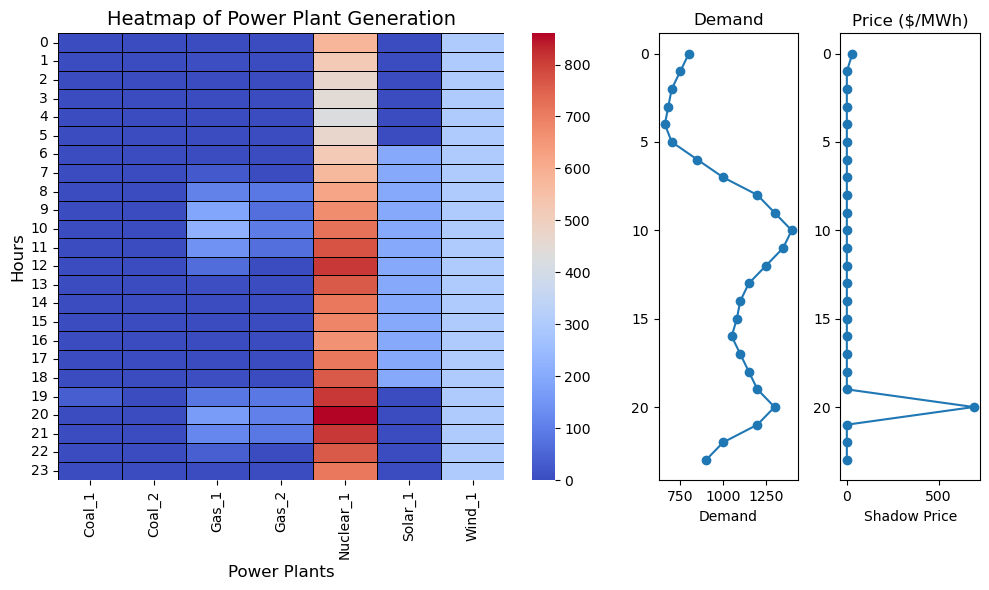

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2, ax3) = plt.subplots(ncols=3, figsize=(10, 6), gridspec_kw={'width_ratios': [8, 2, 2]})

# Plot Power Generation Heatmap
df = generation.unstack()
df.columns = df.columns.droplevel(0)
ax = sns.heatmap(df.T, ax=ax1, annot=False, fmt=".1f", cmap="coolwarm", linewidths=0.5, linecolor="black")
ax1.set_title("Heatmap of Power Plant Generation", fontsize=14)
ax1.set_xlabel("Power Plants", fontsize=12)
ax1.set_ylabel("Hours", fontsize=12)
ax1.tick_params(axis="x", rotation=90)
ax1.tick_params(axis="y", rotation=0)

# Plot Demand Line Chart
ax2.plot(demand.values, demand.index, marker='o')
ax2.set_title("Demand", fontsize=12)
ax2.set_xlabel("Demand")
ax2.set_ylabel("")
ax2.invert_yaxis()

# Plot Price Line Chart
ax3.plot(prices.values, prices.index, marker='o')
ax3.set_title("Price ($/MWh)", fontsize=12)
ax3.set_xlabel("Shadow Price")
ax3.set_ylabel("")
ax3.invert_yaxis()

plt.tight_layout()
plt.show()